In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler 

In [3]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=4, random_state=42)

In [7]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
df

,Feature_1,Feature_2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868
...,...,...
495,-1.282205,-3.181575
496,-2.817604,10.378894
497,3.296740,8.649256
498,-8.970519,-2.684073


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df) 

In [12]:
inertia = []
k_range = range(1,11) 

In [17]:
for k in k_range:
    kmeans = KMeans(n_clusters=k,random_state=42) 
    kmeans.fit(X_scaled) 
    inertia.append(kmeans.inertia_)  

In [18]:
inertia

[999.9999999999993,
 528.8064432605648,
 294.4377068678187,
 250.45524696534443,
 216.88110656982602,
 185.27440675195902,
 156.7087999629044,
 135.62603453115247,
 129.1039634823981,
 119.94101297104989]

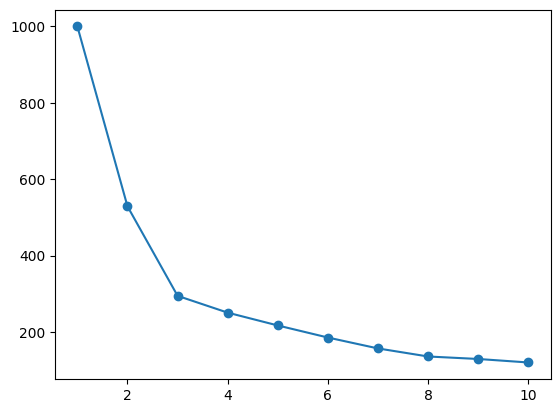

In [20]:
plt.plot(k_range,inertia,marker='o')

In [32]:
kmeans_final = KMeans(n_clusters=2, random_state=42)

In [33]:
cluster_labels = kmeans_final.fit_predict(X_scaled) 

In [34]:
df['cluster'] = cluster_labels 

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

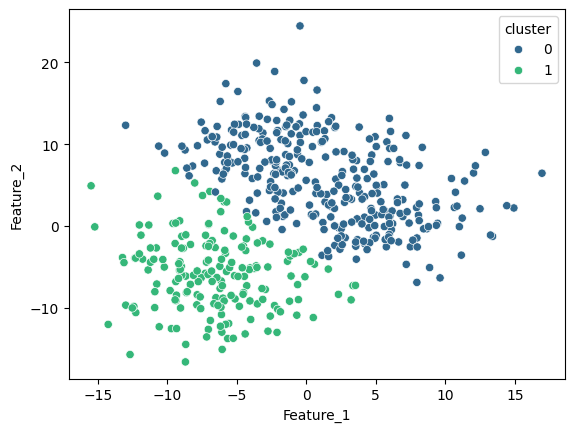

In [35]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'], 
                hue=df['cluster'], 
                palette='viridis')  